In [39]:
import geopandas as gpd
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
import matplotlib as mpl

In [7]:
gdf_data = gpd.read_file(r"D:\Profiles\Tim\Documents\Community Response\Codebase\validation\temporary_gdf.geojson")

In [59]:
cols = ["p_children", "mean_adult_age", "p_level_4", "p_green_heating", "p_married", "p_born_in_UK", "p_L1_to_L6", "p_religion", "p_nonchristian_religion", "p_owned", "p_car_drive_commute", "total_route_exposure"]

gdf_data_reduced = gdf_data.loc[:,cols + ["empirical", "geometry"]]
# For exclusion of Dundee City:
# gdf_data_reduced = gdf_data.loc[~(gdf_data["council"] == "S12000042"),cols + ["empirical", "geometry"]]

In [60]:
gdf_data

,2021 output area,aggregation_small,LSOA21NM,aggregation_medium,council,empirical,modelled,squared_error,p_children,mean_adult_age,...,p_green_heating,p_married,p_born_in_UK,p_L1_to_L6,p_religion,p_nonchristian_religion,p_owned,p_car_drive_commute,total_route_exposure,geometry
0,S00139512,S01014253,0.0,S02002646,S12000041,0.0,0.954179,0.910458,0.311765,48.589744,...,0.000000,0.289157,0.780488,0.157025,0.357143,0.053571,0.211765,0.533333,0.328992,"MULTIPOLYGON (((360204.798 759660.783, 360115...."
1,S00139498,S01014253,0.0,S02002646,S12000041,0.0,0.896055,0.802914,0.234043,47.055556,...,0.000000,0.293478,0.921348,0.432432,0.382979,0.000000,0.573034,0.619048,0.183282,"MULTIPOLYGON (((360229.881 759863.237, 360224 ..."
2,S00139489,S01014254,0.0,S02002646,S12000041,0.0,0.029794,0.000888,0.312500,45.259740,...,0.000000,0.271028,0.864865,0.256098,0.289720,0.018692,0.477064,0.627451,0.256110,"MULTIPOLYGON (((360308.15 759886.07, 360322.04..."
3,S00139523,S01014251,0.0,S02002646,S12000041,0.0,0.949706,0.901942,0.172727,46.120879,...,0.000000,0.112245,0.913978,0.144578,0.387755,0.142857,0.163265,0.500000,0.144862,"MULTIPOLYGON (((360439.001 759296, 360406.83 7..."
4,S00139505,S01014252,0.0,S02002646,S12000041,0.0,0.254148,0.064591,0.146067,51.105263,...,0.000000,0.241379,0.865169,0.166667,0.337209,0.000000,0.356322,0.512195,0.166509,"MULTIPOLYGON (((360421.023 759743.892, 360404...."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2475,S00139256,S01013827,0.0,S02002572,S12000034,0.0,0.734549,0.539563,0.401869,42.937500,...,0.000000,0.594595,0.938596,0.567568,0.198198,0.000000,0.945946,0.692308,0.012861,"MULTIPOLYGON (((387504 785403, 387448 785457, ..."
2476,S00139257,S01013826,0.0,S02002572,S12000034,0.0,0.349508,0.122156,0.051948,53.328767,...,0.000000,0.223529,0.903614,0.324675,0.392857,0.000000,0.602410,0.326087,0.006177,"MULTIPOLYGON (((387608 785471, 387599 785474, ..."
2477,S00139259,S01013827,0.0,S02002572,S12000034,0.0,0.263107,0.069225,0.373239,48.707865,...,0.000000,0.726027,0.931507,0.626263,0.328859,0.000000,0.900000,0.471429,0.023628,"MULTIPOLYGON (((387100.104 785224.352, 387083...."
2478,S00139262,S01013827,0.0,S02002572,S12000034,1.0,0.141122,0.737672,0.329032,47.423077,...,0.000000,0.739726,0.877551,0.464912,0.360544,0.000000,0.973154,0.447368,0.019113,"MULTIPOLYGON (((387074.365 785168.365, 387070...."


In [61]:

X = np.array(gdf_data_reduced.loc[:,cols].fillna(0.0))
# y = 1 * x_0 + 2 * x_1 + 3
y = np.array(gdf_data_reduced.loc[:,"empirical"])
reg = LinearRegression().fit(X, y)
reg.score(X, y)

# reg.coef_
# array([1., 2.])
# reg.intercept_
# np.float64(3.0)
# reg.predict(np.array([[3, 5]]))

0.20522039557387362

In [62]:
dict(zip(gdf_data_reduced.iloc[:,:-1].columns,reg.coef_))

{'p_children': np.float64(-0.058492340647504026),
 'mean_adult_age': np.float64(0.003537504289905262),
 'p_level_4': np.float64(0.6163184883654477),
 'p_green_heating': np.float64(-0.2249844130517635),
 'p_married': np.float64(0.15086887452650047),
 'p_born_in_UK': np.float64(0.05425646610330216),
 'p_L1_to_L6': np.float64(-0.4571973621243832),
 'p_religion': np.float64(0.12131648021396628),
 'p_nonchristian_religion': np.float64(-0.30776802613741433),
 'p_owned': np.float64(-0.05877946117203358),
 'p_car_drive_commute': np.float64(-0.015309148542851845),
 'total_route_exposure': np.float64(0.1471575299625802)}

In [63]:
gdf_data_reduced["predicted"] = reg.predict(X)

In [64]:
(gdf_data_reduced.loc[:,["predicted", "empirical"]].corr().iloc[0,1],
 gdf_data_reduced.loc[:,["predicted", "empirical"]].corr(method = "spearman").iloc[0,1])

(np.float64(0.4530125777214972), np.float64(0.2214181486989588))

[]

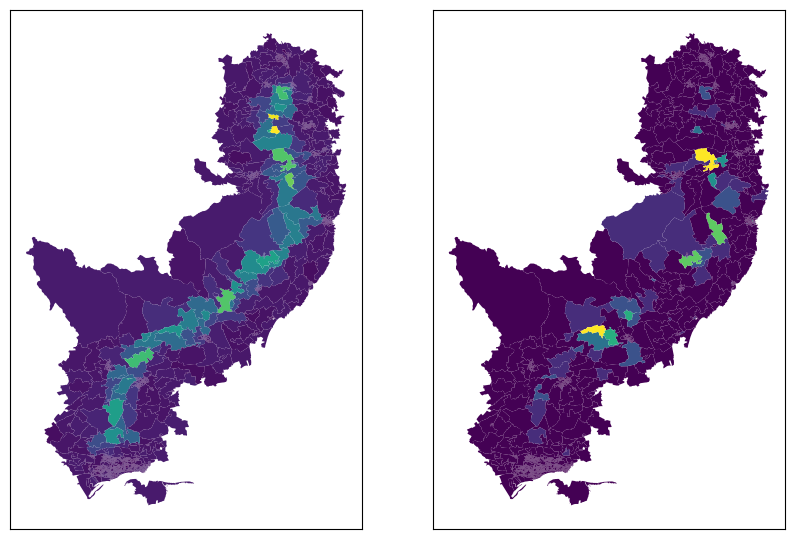

In [66]:
fig, ax = plt.subplots(figsize = (10,10), ncols = 2)
norm = mpl.colors.Normalize(vmin=0, vmax=8)
gdf_data_reduced.plot(column = "predicted", ax = ax[0])
gdf_data_reduced.plot(column = "empirical", ax = ax[1], norm = norm)
ax[0].set_xticks([])
ax[0].set_yticks([])
ax[1].set_xticks([])
ax[1].set_yticks([])

In [52]:
gdf_data_reduced = gdf_data_reduced.sort_values("predicted", ascending = False).iloc[:200, :]
gdf_data_reduced

,p_children,mean_adult_age,p_level_4,p_green_heating,p_married,p_born_in_UK,p_L1_to_L6,p_religion,p_nonchristian_religion,p_owned,p_car_drive_commute,total_route_exposure,empirical,geometry,predicted
182,0.343750,44.342857,0.584746,0.000000,0.745342,0.896970,0.486957,0.441718,0.012270,0.721212,0.523256,23.252197,3.0,"MULTIPOLYGON (((375434 807070, 375326 807103, ...",3.622080
186,0.321429,49.605263,0.488095,0.054348,0.585903,0.925439,0.482955,0.442553,0.004255,0.574561,0.627451,22.992053,0.0,"MULTIPOLYGON (((373593 809806, 373543 809605, ...",3.419349
79,0.265000,51.782313,0.477419,0.033708,0.578947,0.932367,0.558282,0.391960,0.005025,0.898058,0.594059,18.341526,4.0,"MULTIPOLYGON (((378782.574 796779.229, 378707....",2.664282
178,0.306977,51.731544,0.614379,0.090909,0.744186,0.953488,0.490066,0.421296,0.009259,0.855814,0.560000,16.272727,8.0,"MULTIPOLYGON (((377027 802241, 376451 802176, ...",2.585959
1914,0.271523,51.600000,0.406504,0.000000,0.500000,0.980645,0.309735,0.386076,0.000000,0.737179,0.623529,16.619501,1.0,"MULTIPOLYGON (((363787.001 770971, 363790.585 ...",2.577788
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2085,0.277228,51.328767,0.457831,0.000000,0.695238,0.910891,0.536585,0.460784,0.029412,0.961538,0.518519,1.446714,1.0,"MULTIPOLYGON (((378576.933 780983.656, 378576....",0.213418
927,0.158273,54.461538,0.345133,0.000000,0.546154,0.960938,0.285714,0.592000,0.000000,0.776000,0.621212,0.185629,0.0,"MULTIPOLYGON (((336953.001 753000, 337000 7530...",0.212424
220,0.193548,56.830000,0.500000,0.089552,0.511811,0.930233,0.515152,0.528926,0.000000,0.905512,0.508475,0.934953,0.0,"MULTIPOLYGON (((372231 815966, 372201 815986.9...",0.212276
2147,0.227273,52.445378,0.570175,0.018519,0.695035,0.875862,0.525424,0.375000,0.000000,0.896552,0.507692,0.175572,0.0,"MULTIPOLYGON (((383385 800703, 383373.373 8007...",0.210951
